<a href="https://colab.research.google.com/github/iremtuanabayat/su_icilebirlik_makine_ogrenmesi/blob/main/veri_on_isleme.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [49]:
import pandas as pd
import numpy as np
import kagglehub
import os
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report
from sklearn.metrics import precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold, cross_val_predict


In [2]:
path = kagglehub.dataset_download("adityakadiwal/water-potability")

# CSV dosyasının tam yolunu oluştur
csv_path = os.path.join(path, "water_potability.csv")

# Veriyi pandasa okuttuk
df = pd.read_csv(csv_path)
("Veri başarıyla yüklendi!")

100%|██████████| 251k/251k [00:00<00:00, 433kB/s]

Extracting files...


'Veri başarıyla yüklendi!'

In [3]:
(df.head()) #ilk 5 tane satırı görüntüledik

,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
0,NaN,204.890455,20791.318981,7.300212,368.516441,564.308654,10.379783,86.990970,2.963135,0
1,3.716080,129.422921,18630.057858,6.635246,NaN,592.885359,15.180013,56.329076,4.500656,0
2,8.099124,224.236259,19909.541732,9.275884,NaN,418.606213,16.868637,66.420093,3.055934,0
3,8.316766,214.373394,22018.417441,8.059332,356.886136,363.266516,18.436524,100.341674,4.628771,0
4,9.092223,181.101509,17978.986339,6.546600,310.135738,398.410813,11.558279,31.997993,4.075075,0


In [4]:
(df.shape[0]) # su örneği sayısı

3276

In [5]:
(df.shape[1]) #10 tane özellik var


10

In [6]:
(df.shape) # su örneği sayısını ve kaç tane özellik olduğunu kolay yoldan görüntülemek

(3276, 10)

In [7]:
for column in df.columns: #özellikleri her bir sütünda gezerek listeledik
    print(column)

ph
Hardness
Solids
Chloramines
Sulfate
Conductivity
Organic_carbon
Trihalomethanes
Turbidity
Potability


In [8]:
(df.dtypes) #veri tiplerini bulduk

,0
ph,float64
Hardness,float64
Solids,float64
Chloramines,float64
Sulfate,float64
Conductivity,float64
Organic_carbon,float64
Trihalomethanes,float64
Turbidity,float64
Potability,int64


In [9]:
df["Potability"].value_counts() #bu sutün suyun içilebilir olup olmadığı hakkında bilgi veriyor. eğer 1 ise içilebilir 0 ise içilemek

,count
Potability,
0,1998
1,1278


In [10]:
#içilemez su verisi daha fazla veride dengesizlik var

In [11]:
df.isnull().sum() #eksik değerleri çağırıyoruz.

,0
ph,491
Hardness,0
Solids,0
Chloramines,0
Sulfate,781
Conductivity,0
Organic_carbon,0
Trihalomethanes,162
Turbidity,0
Potability,0


In [12]:
print(df.describe()) # min max standart sapma ortalama vb değerleri veriyor

                ph     Hardness        Solids  Chloramines      Sulfate  \
count  2785.000000  3276.000000   3276.000000  3276.000000  2495.000000   
mean      7.080795   196.369496  22014.092526     7.122277   333.775777   
std       1.594320    32.879761   8768.570828     1.583085    41.416840   
min       0.000000    47.432000    320.942611     0.352000   129.000000   
25%       6.093092   176.850538  15666.690297     6.127421   307.699498   
50%       7.036752   196.967627  20927.833607     7.130299   333.073546   
75%       8.062066   216.667456  27332.762127     8.114887   359.950170   
max      14.000000   323.124000  61227.196008    13.127000   481.030642   

       Conductivity  Organic_carbon  Trihalomethanes    Turbidity   Potability  
count   3276.000000     3276.000000      3114.000000  3276.000000  3276.000000  
mean     426.205111       14.284970        66.396293     3.966786     0.390110  
std       80.824064        3.308162        16.175008     0.780382     0.487849  


In [13]:
X = df.drop("Potability", axis=1) #sutünların arasından potability yani içilebilirlik değerini çıkartıp y değişkenine atıyoruz
y = df["Potability"] #sadece potability değerini y değişkenine atadık.

In [14]:
X #potability yok

,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity
0,NaN,204.890455,20791.318981,7.300212,368.516441,564.308654,10.379783,86.990970,2.963135
1,3.716080,129.422921,18630.057858,6.635246,NaN,592.885359,15.180013,56.329076,4.500656
2,8.099124,224.236259,19909.541732,9.275884,NaN,418.606213,16.868637,66.420093,3.055934
3,8.316766,214.373394,22018.417441,8.059332,356.886136,363.266516,18.436524,100.341674,4.628771
4,9.092223,181.101509,17978.986339,6.546600,310.135738,398.410813,11.558279,31.997993,4.075075
...,...,...,...,...,...,...,...,...,...
3271,4.668102,193.681735,47580.991603,7.166639,359.948574,526.424171,13.894419,66.687695,4.435821
3272,7.808856,193.553212,17329.802160,8.061362,NaN,392.449580,19.903225,NaN,2.798243
3273,9.419510,175.762646,33155.578218,7.350233,NaN,432.044783,11.039070,69.845400,3.298875
3274,5.126763,230.603758,11983.869376,6.303357,NaN,402.883113,11.168946,77.488213,4.708658


In [15]:
y #sadece potability sutunu

,Potability
0,0
1,0
2,0
3,0
4,0
...,...
3271,1
3272,1
3273,1
3274,1


In [16]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

train_test_split eğitim ve test verisinin ayrılmasını sağlıyor.yüzde 80 eğitim verisi, yüzde 20 test verisi olarak veriyi ayırdık.
random_state veriyi ayırırken hangi gruplara gideceğini belirler.
stratify=y, eğitim ve test kümelerinde içilebilir (1) ve içilebilir olmayan (0) su örneklerinin oranlarını, tüm veri setindeki oranlara yakın tutar.

eksik değerleri medyanla doldurmayı tercih ettim

In [17]:
imputer = SimpleImputer(strategy="median") #simpleımputer kullanara medyan değerle doldurmayı tercih ettim.
# veri sızıntısı olmaması için x train ve x testi ayrı ayrı medyanla doldurdum
X_train = imputer.fit_transform(X_train)
X_test = imputer.transform(X_test)

In [18]:
(X_train.shape)

(2620, 9)

In [19]:
(X_test.shape)

(656, 9)

In [20]:
print(np.isnan(X_train).sum()) # x train ve x testte boş değerler var mı diye kontrol ettik
print(np.isnan(X_test).sum())

0
0


In [21]:
scaler = StandardScaler() # modeli ölçeklendirmek için

X_train_scaled = scaler.fit_transform(X_train) #Ölçeklendirme için gerekli ortalama ve standart sapmaları eğitim verisinden öğrenir ve eğitim verisini dönüştürür.
X_test_scaled = scaler.transform(X_test) #Test verisini, eğitim verisinden öğrenilen aynı değerlerle dönüştürür.
model = LogisticRegression(max_iter=1000) #1000 iterasyonla eğitir.
model.fit(X_train_scaled, y_train)

LogisticRegression(max_iter=1000)

In [22]:
y_pred = model.predict(X_test_scaled)
# x_test_scaled modelin ölçeklendirilmiş test verisi. y_pred modelin tahmini.
print("Gerçek değerler:", y_test[:10].to_numpy())
print("Model tahminleri:", y_pred[:10])

Gerçek değerler: [1 0 0 0 0 0 0 0 1 1]
Model tahminleri: [0 0 0 0 0 0 0 0 0 0]


In [23]:
accuracy = accuracy_score(y_test, y_pred) # test ve modelin tahmininin doğruluk oranını karşılaştıracağız.
print("Doğruluk oranı:", accuracy)

Doğruluk oranı: 0.6097560975609756


In [24]:
report = classification_report( #f1 skoru gibi başarı oranlarını gösterir
    y_test,
    y_pred,
    output_dict=True,# raporu metin yerine python sözlüğü olarak yazdırır
    zero_division=0 #hesaplanamayan metriği 0 gösterir
)

report_df = pd.DataFrame(report).T

print(report_df.round(2)) #oluşturduğumuz tabloda virgülden sonraki satırları yuvarlar

              precision  recall  f1-score  support
0                  0.61    1.00      0.76   400.00
1                  0.00    0.00      0.00   256.00
accuracy           0.61    0.61      0.61     0.61
macro avg          0.30    0.50      0.38   656.00
weighted avg       0.37    0.61      0.46   656.00


precision ve recall değerlerinin analizine göre 0 değeri doğru tahmin edilmiş. modelin doğruluk oranı ile 0 oranı aynı. model hepsini 0 mı tahmin etmiş onu kontrol edeceğiz.

In [25]:
np.unique(y_pred, return_counts=True) #modelin tahmin ettiği her farklı değeri ve bunun sayısını verir

(array([0]), array([656]))

model 656 tane içme suyunun hepsine içilemez değeri vermiş

In [26]:
print("Gerçek sınıflar:")
print(np.unique(y_test, return_counts=True))

print("Modelin tahminleri:")
print(np.unique(y_pred, return_counts=True))

Gerçek sınıflar:
(array([0, 1]), array([400, 256]))
Modelin tahminleri:
(array([0]), array([656]))


In [27]:
y_train_pred = model.predict(X_train_scaled)

print("Eğitim tahminleri:")
print(np.unique(y_train_pred, return_counts=True))

print("Test tahminleri:")
print(np.unique(y_pred, return_counts=True))

Eğitim tahminleri:
(array([0]), array([2620]))
Test tahminleri:
(array([0]), array([656]))


In [28]:
y_proba = model.predict_proba(X_test_scaled) # predict_proba = her örneğin her sınıfa ait olma olasılığini y_proba değişkenine atadık

print(y_proba[:10]) #ilk 10 değer için

[[0.62325908 0.37674092]
 [0.64072267 0.35927733]
 [0.59990158 0.40009842]
 [0.56869341 0.43130659]
 [0.60657021 0.39342979]
 [0.6240805  0.3759195 ]
 [0.61324858 0.38675142]
 [0.59269445 0.40730555]
 [0.6254598  0.3745402 ]
 [0.60231398 0.39768602]]


Model, her satırda olasılığı daha yüksek olan sınıfı seçiyor. İlk 10 satırda da 0 olasılığı daha yüksek olduğu için hepsini 0 tahmin etmiş.

In [29]:
print("En yüksek 1 sınıfı olasılığı:")
print(y_proba[:, 1].max())


En yüksek 1 sınıfı olasılığı:
0.47973919713146235


en yüksek 1 sınıfı olasılığını 0.5'den düşük bulduğumuz için bu olasılıklarla oynayıp modelin daha iyi tahmin yapıp yapmadığını ölçeceğim ve 0.45 ve üzerindeyse model içilebilir tahmininde bulunacak

In [30]:
y_pred_new = (y_proba[:, 1] >= 0.45).astype(int)

print(np.unique(y_pred_new, return_counts=True))
print(classification_report(
    y_test,
    y_pred_new,
    zero_division=0
))

(array([0, 1]), array([651,   5]))
              precision    recall  f1-score   support

           0       0.61      1.00      0.76       400
           1       1.00      0.02      0.04       256

    accuracy                           0.62       656
   macro avg       0.81      0.51      0.40       656
weighted avg       0.76      0.62      0.48       656



0 değerini 651 defa tahmin etmişken 1 değerini yalnızca beş kere tahmin etmiş. doğruluk oranı 0.61'den 0.62'ye yükselmiş.

farklı eşik değerlerinde classification hesaplayıp uygun eşik değerini seçeceğim

In [31]:
for threshold in [0.45, 0.40, 0.35, 0.30, 0.25]:
    y_pred_threshold = (y_proba[:, 1] >= threshold).astype(int)

    print("\nEşik değeri:", threshold)

    print("Sınıf dağılımı:")
    print(np.unique(y_pred_threshold, return_counts=True))

    print("Accuracy:", round(accuracy_score(y_test, y_pred_threshold), 2))
    print("Precision:", round(precision_score(y_test, y_pred_threshold, zero_division=0), 2))
    print("Recall:", round(recall_score(y_test, y_pred_threshold, zero_division=0), 2))
    print("F1-score:", round(f1_score(y_test, y_pred_threshold, zero_division=0), 2))


Eşik değeri: 0.45
Sınıf dağılımı:
(array([0, 1]), array([651,   5]))
Accuracy: 0.62
Precision: 1.0
Recall: 0.02
F1-score: 0.04

Eşik değeri: 0.4
Sınıf dağılımı:
(array([0, 1]), array([451, 205]))
Accuracy: 0.6
Precision: 0.48
Recall: 0.39
F1-score: 0.43

Eşik değeri: 0.35
Sınıf dağılımı:
(array([0, 1]), array([ 13, 643]))
Accuracy: 0.39
Precision: 0.39
Recall: 0.97
F1-score: 0.55

Eşik değeri: 0.3
Sınıf dağılımı:
(array([1]), array([656]))
Accuracy: 0.39
Precision: 0.39
Recall: 1.0
F1-score: 0.56

Eşik değeri: 0.25
Sınıf dağılımı:
(array([1]), array([656]))
Accuracy: 0.39
Precision: 0.39
Recall: 1.0
F1-score: 0.56


Accuracy tüm doğru tahminlerin oranını ölçer.
Precision, 1 denilen örneklerin ne kadarının gerçekten 1 olduğunu ölçer.
Recall, gerçek 1 örneklerinin ne kadarının bulunduğunu ölçer.

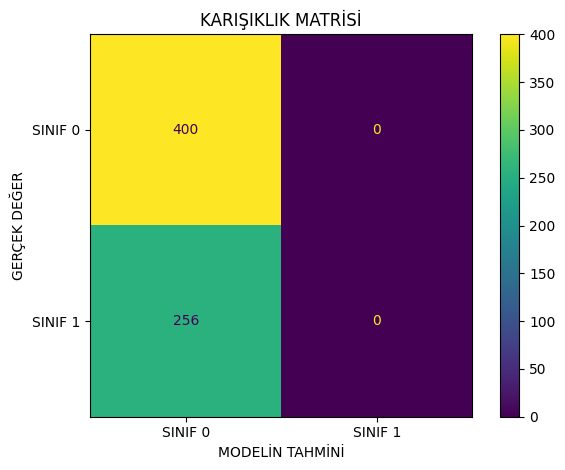

In [32]:

import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# GERÇEK DEĞERLER İLE MODEL TAHMİNLERİNİ KARŞILAŞTIR
cm = confusion_matrix(y_test, y_pred)

# KARIŞIKLIK MATRİSİNİ OLUŞTUR VE SINIF İSİMLERİNİ BELİRLE
display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["SINIF 0", "SINIF 1"]
)

# GRAFİĞİ OLUŞTUR
display.plot()

# GRAFİĞİN BAŞLIĞINI BELİRLE
plt.title("KARIŞIKLIK MATRİSİ")

# YATAY EKSENİ MODELİN TAHMİNLERİ OLARAK ADLANDIR
plt.xlabel("MODELİN TAHMİNİ")

# DİKEY EKSENİ GERÇEK DEĞERLER OLARAK ADLANDIR
plt.ylabel("GERÇEK DEĞER")

# EKSENLERDEKİ SINIF İSİMLERİNİ BÜYÜK HARFLERLE GÖSTER
plt.xticks([0, 1], ["SINIF 0", "SINIF 1"], rotation=0)
plt.yticks([0, 1], ["SINIF 0", "SINIF 1"], rotation=0)

# GRAFİĞİN DÜZENİNİ AYARLA
plt.tight_layout()

# GRAFİĞİ EKRANDA GÖSTER
plt.show()


Logistic Regression modelini eğitip test verileri üzerinde değerlendirdik. Model, varsayılan karar eşiğinde bütün örnekleri 0 sınıfı olarak tahmin etti ve yaklaşık %61 doğruluk oranı elde etti. Bu oran, veri setinde çoğunlukta olan 0 sınıfını sürekli tahmin ederek de elde edilebilecek bir seviyedeydi.

Karar eşiğini değiştirdiğimizde sınıf tahminlerinin dağılımı değişti; ancak accuracy ve diğer performans metrikleri arasında bir denge kurmak gerektiğini gördük. Bu nedenle Logistic Regression modelinin mevcut ayarlarla iki sınıfı yeterince ayırt edemediğini düşündük ve performansını farklı sınıflandırma algoritmalarıyla karşılaştırmaya karar verdik. Şimdi random forest algoritmasını deneyeceğim.

In [33]:
# RANDOM FOREST MODELİNİ OLUŞTUR
rf_model = RandomForestClassifier(
    n_estimators=100, #ormanda 100 karar ağacı oluşturulmasını ister.
    random_state=42 #gruplara ayırmayı sabitler
)

# MODELİ EĞİTİM VERİLERİYLE EĞİT
rf_model.fit(X_train, y_train)

# MODELİN EĞİTİLDİĞİNİ KONTROL ET
print("RANDOM FOREST MODELİ EĞİTİLDİ.")

RANDOM FOREST MODELİ EĞİTİLDİ.


In [34]:

# TEST VERİLERİ ÜZERİNDE TAHMİN YAP
y_pred_rf = rf_model.predict(X_test)

# MODELİN HANGİ SINIFLARI KAÇ KEZ TAHMİN ETTİĞİNİ GÖSTER
import numpy as np

print(np.unique(y_pred_rf, return_counts=True))


(array([0, 1]), array([535, 121]))


In [35]:

# MODEL DEĞERLENDİRME ARAÇLARINI İÇE AKTAR
from sklearn.metrics import accuracy_score, classification_report

# DOĞRU TAHMİNLERİN ORANINI HESAPLA
accuracy_rf = accuracy_score(y_test, y_pred_rf)
print("DOĞRULUK:", round(accuracy_rf, 3))

# HER SINIF İÇİN AYRINTILI BAŞARI RAPORUNU GÖSTER
print(classification_report(y_test, y_pred_rf, zero_division=0))


DOĞRULUK: 0.663
              precision    recall  f1-score   support

           0       0.67      0.89      0.76       400
           1       0.64      0.30      0.41       256

    accuracy                           0.66       656
   macro avg       0.66      0.60      0.59       656
weighted avg       0.66      0.66      0.63       656



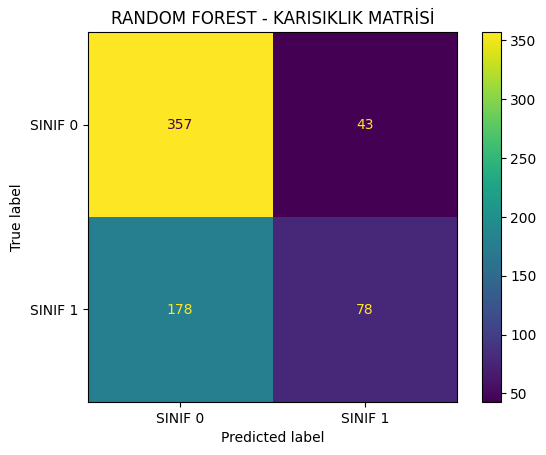

In [36]:
# GERÇEK DEĞERLER İLE TAHMİNLERİ KARŞILAŞTIR
cm_rf = confusion_matrix(y_test, y_pred_rf)

# MATRİSİ OLUŞTUR
display_rf = ConfusionMatrixDisplay(
    confusion_matrix=cm_rf,
    display_labels=["SINIF 0", "SINIF 1"]
)

# MATRİSİ GÖRSELLEŞTİR
display_rf.plot()

# GRAFİĞE BAŞLIK EKLE
plt.title("RANDOM FOREST - KARISIKLIK MATRİSİ")

# GRAFİĞİ GÖSTER
plt.show()

yüzde 66 gibi bir doğruluk oranı aldık. şimdi model neye önem vererek bu tahmini yapmış onu hesaplayacağız


In [37]:
# ÖZELLİKLERİN İSİMLERİNİ VE RANDOM FOREST MODELİNİN ÖNEM PUANLARINI
# BİR ARAYA GETİREREK YENİ BİR DATAFRAME (VERİ TABLOSU) OLUŞTUR
importance_df = pd.DataFrame({

    # ORİJİNAL VERİ SETİNDEN POTABILITY SÜTUNUNU ÇIKAR
    # AXIS=1, SÜTUNLAR ÜZERİNDE İŞLEM YAPILACAĞINI BELİRTİR
    # COLUMNS, GERİYE KALAN 9 ÖZELLİĞİN İSİMLERİNİ GETİRİR
    "ÖZELLİK": df.drop("Potability", axis=1).columns,

    # RANDOM FOREST MODELİNİN HER ÖZELLİK İÇİN HESAPLADIĞI ÖNEM PUANLARINI AL
    "ÖNEM": rf_model.feature_importances_
})

# OLUŞTURDUĞUMUZ TABLOYU ÖNEM PUANINA GÖRE SIRALA
importance_df = importance_df.sort_values(

    # SIRALAMANIN HANGİ SÜTUNA GÖRE YAPILACAĞINI BELİRLE
    by="ÖNEM",

    # ASCENDING=FALSE, DEĞERLERİ BÜYÜKTEN KÜÇÜĞE SIRALAR
    # BÖYLECE MODELDE EN ÖNEMLİ GÖRÜNEN ÖZELLİK EN ÜSTTE YER ALIR
    ascending=False
)

# ÖNEM PUANLARINI VİRGÜLDEN SONRA 3 BASAMAK OLACAK ŞEKİLDE GÖSTER
print(importance_df.round(3))


           ÖZELLİK   ÖNEM
0               ph  0.129
4          Sulfate  0.128
1         Hardness  0.122
3      Chloramines  0.116
2           Solids  0.112
8        Turbidity  0.100
5     Conductivity  0.100
6   Organic_carbon  0.097
7  Trihalomethanes  0.096


In [38]:
# DENEYECEĞİMİZ KARAR AĞACI DERİNLİKLERİNİ BİR LİSTEDE TANIMLA
# MAX_DEPTH, RANDOM FOREST İÇİNDEKİ HER BİR KARAR AĞACININ ULAŞABİLECEĞİ MAKSİMUM DERİNLİĞİ BELİRLER
# NONE, AĞAÇ DERİNLİĞİ İÇİN BELİRLİ BİR ÜST SINIR KOYMAMAK DEMEKTİR
depth_values = [3, 5, 10, 15, 20, None]


# HER DERİNLİKTE ELDE EDİLEN SONUÇLARI SAKLAMAK İÇİN BOŞ BİR LİSTE OLUŞTUR
results = []


# DEPTH_VALUES LİSTESİNDEKİ HER DERİNLİK DEĞERİNİ SIRASIYLA ELE AL
# HER TURDA YENİ BİR MODEL EĞİTİLİR VE SONUÇLARI ÖLÇÜLÜR
for depth in depth_values:

    # SEÇİLEN DERİNLİK DEĞERİYLE YENİ BİR RANDOM FOREST MODELİ OLUŞTUR
    rf_model_depth = RandomForestClassifier(

        # MODELİN İÇİNDE 100 ADET KARAR AĞACI BULUNMASINI SAĞLA
        n_estimators=100,

        # KARAR AĞAÇLARININ MAKSİMUM DERİNLİĞİNİ DÖNGÜDEKİ DEĞERE AYARLA
        max_depth=depth,

        # RASTGELELİĞİ SABİT TUTARAK AYNI AYARLARLA TEKRARLANABİLİR SONUÇ AL
        random_state=42
    )

    # MODELİ EĞİTİM VERİLERİYLE EĞİT
    # X_TRAIN, SU ÖRNEKLERİNİN ÖZELLİKLERİNİ İÇERİR
    # Y_TRAIN, HER ÖRNEĞİN GERÇEK SINIFINI (0 VEYA 1) İÇERİR
    # FIT(), MODELİN ÖZELLİKLER İLE SINIFLAR ARASINDAKİ ÖRÜNTÜLERİ ÖĞRENMESİNİ SAĞLAR
    rf_model_depth.fit(X_train, y_train)

    # EĞİTİLMİŞ MODELİ KULLANARAK DAHA ÖNCE EĞİTİMDE KULLANILMAYAN TEST VERİLERİNİN SINIFLARINI TAHMİN ET
    # HER TEST ÖRNEĞİ İÇİN 0 VEYA 1 TAHMİNİ ÜRETİLİR
    y_pred_depth = rf_model_depth.predict(X_test)

    # MODELİN SINIF 0 VE SINIF 1 İÇİN KAÇ TAHMİN ÜRETTİĞİNİ HESAPLA
    # NP.UNIQUE() TAHMİNLERDEKİ FARKLI SINIF DEĞERLERİNİ BULUR
    # RETURN_COUNTS=TRUE, HER SINIFIN KAÇ KEZ GÖRÜLDÜĞÜNÜ DE DÖNDÜRÜR
    class_counts = np.unique(y_pred_depth, return_counts=True)

    # BU MODELİN DERİNLİK DEĞERİNİ VE PERFORMANS SONUÇLARINI SÖZLÜK OLARAK KAYDET
    results.append({

        # TEST ETTİĞİMİZ KARAR AĞACI DERİNLİĞİNİ KAYDET
        "MAX_DEPTH": depth,

        # MODELİN 0 VE 1 SINIFLARINI KAÇ KEZ TAHMİN ETTİĞİNİ KAYDET
        "TAHMİN DAĞILIMI (SINIF, SAYI)": class_counts,
        "ACCURACY": accuracy_score(y_test, y_pred_depth),
        "F1_SCORE": f1_score(y_test, y_pred_depth, zero_division=0),
        "RECALL": recall_score(y_test, y_pred_depth, zero_division=0)
    })

results_df = pd.DataFrame(results)

# SAYISAL SONUÇLARI VİRGÜLDEN SONRA 3 BASAMAKLA GÖSTER
# TO_STRING(INDEX=FALSE), TABLONUN SOLUNDAKİ OTOMATİK SATIR NUMARALARINI GİZLER
print(results_df.round(3).to_string(index=False))


 MAX_DEPTH TAHMİN DAĞILIMI (SINIF, SAYI)  ACCURACY  F1_SCORE  RECALL
       3.0           ([0, 1], [635, 21])     0.627     0.116   0.062
       5.0           ([0, 1], [621, 35])     0.642     0.192   0.109
      10.0           ([0, 1], [581, 75])     0.669     0.344   0.223
      15.0          ([0, 1], [554, 102])     0.668     0.391   0.273
      20.0          ([0, 1], [534, 122])     0.643     0.381   0.281
       NaN          ([0, 1], [535, 121])     0.663     0.414   0.305


In [39]:
# RANDOM FOREST MODELİNİ OLUŞTUR
# RANDOM_STATE=42, SONUÇLARIN TEKRARLANABİLİRLİĞİNİ ARTIRIR
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# DENENECEK MAX_DEPTH DEĞERLERİNİ BELİRLE
# NONE, DERİNLİK İÇİN ÜST SINIR KONULMAMASI DEMEKTİR
param_grid = {
    "max_depth": [3, 5, 10, 15, 20, None]
}

# PARAMETRELERİ 5 KATLI ÇAPRAZ DOĞRULAMAYLA KARŞILAŞTIR
# SCORING="F1", SINIF 1 İÇİN F1-SCORE DEĞERİNİ ÖLÇER
# CV=5, EĞİTİM VERİSİNİ 5 PARÇAYA AYIRARAK DEĞERLENDİRİR
# N_JOBS=-1, MÜMKÜN OLAN TÜM İŞLEMCİ ÇEKİRDEKLERİNİ KULLANIR
grid_search = GridSearchCV(
    estimator=rf_model,
    param_grid=param_grid,
    scoring="f1",
    cv=5,
    n_jobs=-1
)

# PARAMETRE ARAMASINI YALNIZCA EĞİTİM VERİLERİNDE GERÇEKLEŞTİR
grid_search.fit(X_train, y_train)

# ÇAPRAZ DOĞRULAMADA EN İYİ BULUNAN PARAMETREYİ GÖSTER
print("EN İYİ PARAMETRELER:", grid_search.best_params_)

# EN İYİ PARAMETRENİN ORTALAMA ÇAPRAZ DOĞRULAMA F1-SCORE DEĞERİNİ GÖSTER
print("EN İYİ CV F1-SCORE:", round(grid_search.best_score_, 3))
# ÇAPRAZ DOĞRULAMADA EN İYİ BULUNAN MODELİ AL
best_rf_model = grid_search.best_estimator_

# TEST VERİLERİ ÜZERİNDE TAHMİN YAP
y_pred_best = best_rf_model.predict(X_test)

# MODELİN DOĞRULUK DEĞERİNİ HESAPLA
print("TEST ACCURACY:", round(accuracy_score(y_test, y_pred_best), 3))

# SINIF 0 VE SINIF 1'İN KAÇ KEZ TAHMİN EDİLDİĞİNİ HESAPLA
# NP.UNIQUE, TAHMİNLERDEKİ FARKLI SINIFLARI BULUR
# RETURN_COUNTS=TRUE, HER SINIFIN TAHMİN SAYISINI DA DÖNDÜRÜR
unique_values = np.unique(y_pred_best, return_counts=True)

# BULUNAN SINIFLARI VE TAHMİN SAYILARINI EKRANA YAZDIR
print("SINIFLAR VE TAHMİN SAYILARI:", unique_values)

# PRECISION, RECALL VE F1-SCORE DEĞERLERİNİ GÖSTER
print(classification_report(y_test, y_pred_best, zero_division=0))


EN İYİ PARAMETRELER: {'max_depth': 20}
EN İYİ CV F1-SCORE: 0.451
TEST ACCURACY: 0.643
SINIFLAR VE TAHMİN SAYILARI: (array([0, 1]), array([534, 122]))
              precision    recall  f1-score   support

           0       0.66      0.88      0.75       400
           1       0.59      0.28      0.38       256

    accuracy                           0.64       656
   macro avg       0.62      0.58      0.57       656
weighted avg       0.63      0.64      0.61       656



In [40]:

# RANDOM FOREST SINIFLANDIRMA ALGORİTMASINI İÇE AKTARIYORUZ
# BU ALGORİTMA, BİRDEN FAZLA KARAR AĞACINI BİRLEŞTİREREK TAHMİN YAPAR
from sklearn.ensemble import RandomForestClassifier

# GRIDSEARCHCV, FARKLI PARAMETRE KOMBİNASYONLARINI OTOMATİK OLARAK DENER
# CV İSE ÇAPRAZ DOĞRULAMA ANLAMINA GELİR
from sklearn.model_selection import GridSearchCV

# SONUÇLARI TABLOYA DÖNÜŞTÜRMEK VE DÜZENLEMEK İÇİN PANDAS'I İÇE AKTARIYORUZ
import pandas as pd


# --------------------------------------------------
# 1. RANDOM FOREST MODELİNİ OLUŞTURUYORUZ
# --------------------------------------------------

rf_model = RandomForestClassifier(
    n_estimators=100,  # MODEL 100 FARKLI KARAR AĞACI KULLANACAK
    max_depth=None,    # AĞAÇLARIN MAKSİMUM DERİNLİĞİNE SINIR KOYMUYORUZ
    random_state=42    # SONUÇLARIN TEKRARLANABİLMESİ İÇİN SABİT DEĞER KULLANIYORUZ
)


# --------------------------------------------------
# 2. DENENECEK PARAMETRELERİ BELİRLİYORUZ
# --------------------------------------------------

param_grid = {
    # min_samples_leaf: BİR YAPRAK DÜĞÜMDE BULUNMASI GEREKEN
    # EN AZ ÖRNEK SAYISINI BELİRLER.
    # ÖRNEĞİN 4 OLURSA BİR YAPRAKTA EN AZ 4 EĞİTİM ÖRNEĞİ BULUNMALIDIR.
    "min_samples_leaf": [1, 2, 4, 8],

    # min_samples_split: BİR DÜĞÜMÜN İKİYE AYRILABİLMESİ İÇİN
    # GEREKEN EN AZ ÖRNEK SAYISINI BELİRLER.
    # ÖRNEĞİN 10 OLURSA, 10'DAN AZ ÖRNEĞİ OLAN BİR DÜĞÜM BÖLÜNMEZ.
    "min_samples_split": [2, 5, 10, 20]
}

# HER PARAMETRE LİSTESİNDE 4 DEĞER VAR.
# 4 x 4 = 16 FARKLI PARAMETRE KOMBİNASYONU TEST EDİLECEK.
# max_depth=None SABİT KALACAK; BÖYLECE DİĞER İKİ PARAMETREYİ İNCELİYORUZ.


# --------------------------------------------------
# 3. GRIDSEARCHCV İLE PARAMETRE ARAMASINI KURUYORUZ
# --------------------------------------------------

grid_search = GridSearchCV(
    estimator=rf_model,      # PARAMETRELERİNİ AYARLAYACAĞIMIZ MODEL
    param_grid=param_grid,   # DENENECEK PARAMETRE DEĞERLERİ
    scoring="f1",            # MODELLERİ 1 SINIFININ F1 SKORUNA GÖRE KARŞILAŞTIR
    cv=5,                    # EĞİTİM VERİSİNİ 5 PARÇALI ÇAPRAZ DOĞRULAMAYLA DEĞERLENDİR
    n_jobs=-1                # İŞLEMCİNİN KULLANILABİLEN TÜM ÇEKİRDEKLERİNİ KULLAN
)

# 16 KOMBİNASYONUN HER BİRİ 5 DOĞRULAMA TURUNDA DEĞERLENDİRİLİR.
# BU NEDENLE TOPLAM 16 x 5 = 80 MODEL EĞİTİMİ GERÇEKLEŞİR.
# MODELİ EĞİTİM VERİSİYLE DEĞERLENDİRİYORUZ
# X_train: MODELİN KULLANACAĞI ÖZELLİKLER
# y_train: MODELİN TAHMİN ETMEYİ ÖĞRENECEĞİ HEDEF SINIFLAR
# TEST VERİSİNİ BU AŞAMADA KULLANMIYORUZ.
grid_search.fit(X_train, y_train)
#EN İYİ PARAMETRELERİ VE F1 SKORUNU GÖSTERİYORUZ
# best_params_: ÇAPRAZ DOĞRULAMADA EN İYİ SONUCU VEREN PARAMETRELER
print("EN İYİ PARAMETRELER:", grid_search.best_params_)
# best_score_: EN İYİ PARAMETRE KOMBİNASYONUNUN
# 5 DOĞRULAMA TURUNDA ELDE ETTİĞİ ORTALAMA F1 SKORU
print(
    "EN İYİ ÇAPRAZ DOĞRULAMA F1:",
    round(grid_search.best_score_, 3)
)
# TÜM PARAMETRE DENEMELERİNİN SONUÇLARINI ALIYORUZ
# cv_results_ İÇİNDE HER PARAMETRE KOMBİNASYONUNA AİT SONUÇLAR BULUNUR.
# BUNLARI DAHA KOLAY İNCELEMEK İÇİN PANDAS TABLOSUNA DÖNÜŞTÜRÜYORUZ.
results_df = pd.DataFrame(grid_search.cv_results_)

# TABLODA SADECE İNCELEMEK İSTEDİĞİMİZ 4 SÜTUNU BIRAKIYORUZ:
# PARAMETRE DEĞERLERİ, ORTALAMA F1 SKORU VE F1 SKORUNUN STANDART SAPMASI.
results_df = results_df[
    [
        "param_min_samples_leaf",
        "param_min_samples_split",
        "mean_test_score",
        "std_test_score"
    ]
]

# ORTALAMA F1 SKORUNU EN YÜKSEKTEN EN DÜŞÜĞE DOĞRU SIRALIYORUZ.
# BÖYLECE EN BAŞARILI PARAMETRE KOMBİNASYONUNU İLK SATIRDA GÖREBİLİRİZ.
results_df = results_df.sort_values(
    by="mean_test_score",
    ascending=False
)
#SÜTUN İSİMLERİNİ DAHA ANLAŞILIR HALE GETİRİYORUZ
results_df = results_df.rename(columns={
    "param_min_samples_leaf": "MIN_SAMPLES_LEAF",
    "param_min_samples_split": "MIN_SAMPLES_SPLIT",
    "mean_test_score": "ORTALAMA_F1",
    "std_test_score": "F1_STANDART_SAPMA"
})
#SONUÇ TABLOSUNU EKRANA YAZDIRIYORUZ
# round(3): SAYILARI VİRGÜLDEN SONRA 3 BASAMAKLA GÖSTERİR.
# to_string(index=False): TABLOYU DÜZENLİ YAZDIRIR VE SATIR NUMARALARINI GİZLER.
print(results_df.round(3).to_string(index=False))


EN İYİ PARAMETRELER: {'min_samples_leaf': 1, 'min_samples_split': 5}
EN İYİ ÇAPRAZ DOĞRULAMA F1: 0.467
 MIN_SAMPLES_LEAF  MIN_SAMPLES_SPLIT  ORTALAMA_F1  F1_STANDART_SAPMA
                1                  5        0.467              0.030
                2                  2        0.464              0.019
                1                 10        0.449              0.017
                1                  2        0.444              0.032
                2                  5        0.441              0.017
                2                 10        0.438              0.017
                4                  5        0.435              0.022
                4                  2        0.435              0.022
                2                 20        0.431              0.017
                1                 20        0.428              0.017
                4                 20        0.414              0.019
                4                 10        0.410              0.023


In [43]:
# RANDOM FOREST MODELİNİ OLUŞTURUYORUZ
# random_state=42 SONUÇLARIN TEKRARLANABİLİRLİĞİNİ SAĞLAR
rf_model = RandomForestClassifier(
    random_state=42,
    n_jobs=1
)

# ŞİMDİLİK DAHA AZ PARAMETRE KOMBİNASYONU DENİYORUZ
param_grid = {
    "max_depth": [10, 20, None],
    "min_samples_leaf": [1, 2],
    "min_samples_split": [2, 5],
    "max_features": ["sqrt"],
    "n_estimators": [100]
}

# MODELLERİ F1 SKORUNA GÖRE KARŞILAŞTIRIYORUZ
grid_search = GridSearchCV(
    estimator=rf_model,
    param_grid=param_grid,
    scoring={
        "accuracy": "accuracy",
        "recall": "recall",
        "f1": "f1"
    },
    cv=5,
    n_jobs=-1,
    refit="f1",
    verbose=2
)

# SADECE EĞİTİM VERİSİNİ KULLANARAK ARAMAYI BAŞLATIYORUZ
grid_search.fit(X_train, y_train)

# EN İYİ PARAMETRELERİ VE ÇAPRAZ DOĞRULAMA SONUÇLARINI GÖSTERİYORUZ
print("EN İYİ PARAMETRELER:", grid_search.best_params_)
print("EN İYİ ORTALAMA F1:", round(grid_search.best_score_, 3))

# HER PARAMETRE KOMBİNASYONUNUN SONUÇLARINI TABLOLAŞTIRIYORUZ
results_df = pd.DataFrame(grid_search.cv_results_)

# ACCURACY, RECALL VE F1 DEĞERLERİNİ GÖSTERİYORUZ
print(
    results_df[
        [
            "param_max_depth",
            "param_min_samples_leaf",
            "param_min_samples_split",
            "mean_test_accuracy",
            "mean_test_recall",
            "mean_test_f1"
        ]
    ]
    .sort_values("mean_test_f1", ascending=False)
    .round(3)
    .to_string(index=False)
)


Fitting 5 folds for each of 12 candidates, totalling 60 fits
EN İYİ PARAMETRELER: {'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_estimators': 100}
EN İYİ ORTALAMA F1: 0.467
param_max_depth  param_min_samples_leaf  param_min_samples_split  mean_test_accuracy  mean_test_recall  mean_test_f1
           None                       1                        5               0.673             0.368         0.467
           None                       2                        2               0.671             0.365         0.464
             20                       1                        2               0.670             0.348         0.451
             20                       1                        5               0.673             0.342         0.449
           None                       1                        2               0.664             0.344         0.444
           None                       2                        5              

In [44]:
# GRIDSEARCHCV'NİN SEÇTİĞİ EN İYİ MODELİ ALIYORUZ
best_model = grid_search.best_estimator_

# MODELİN DAHA ÖNCE GÖRMEDİĞİ TEST VERİSİYLE TAHMİN YAPIYORUZ
y_pred = best_model.predict(X_test)

# TEST DOĞRULUĞUNU HESAPLIYORUZ
print("TEST ACCURACY:", round(accuracy_score(y_test, y_pred), 3))

# GERÇEK SINIFI 1 OLAN ÖRNEKLERİN NE KADARINI YAKALADIĞIMIZI HESAPLIYORUZ
print("TEST RECALL:", round(recall_score(y_test, y_pred), 3))

# PRECISION VE RECALL DENGESİNİ HESAPLIYORUZ
print("TEST F1:", round(f1_score(y_test, y_pred), 3))

# HER SINIF İÇİN AYRINTILI PERFORMANS RAPORU OLUŞTURUYORUZ
print("\nSINIFLANDIRMA RAPORU:")
print(classification_report(y_test, y_pred, zero_division=0))

# DOĞRU VE YANLIŞ TAHMİNLERİ GÖRMEK İÇİN KARIŞIKLIK MATRİSİ OLUŞTURUYORUZ
print("KARIŞIKLIK MATRİSİ:")
print(confusion_matrix(y_test, y_pred))


TEST ACCURACY: 0.671
TEST RECALL: 0.32
TEST F1: 0.432

SINIFLANDIRMA RAPORU:
              precision    recall  f1-score   support

           0       0.67      0.90      0.77       400
           1       0.66      0.32      0.43       256

    accuracy                           0.67       656
   macro avg       0.67      0.61      0.60       656
weighted avg       0.67      0.67      0.64       656

KARIŞIKLIK MATRİSİ:
[[358  42]
 [174  82]]


en iyi model ile test verisini analiz ettik ve yüzde 67 tahmin edebildiğini gördük. karar eşiğini düşürüp daha fazla 1 tahmin etmesini sağlayıp classificatıon değerlerine bakacağız.

In [45]:

# GEREKLİ KÜTÜPHANELERİ İÇE AKTARIYORUZ
import pandas as pd

from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# GRIDSEARCHCV İLE BULDUĞUMUZ EN İYİ PARAMETRELERİ ALIYORUZ
# clone, MODELİN AYARLARINI KOPYALAR; EĞİTİLMİŞ HALİNİ KOPYALAMAZ
best_model = clone(grid_search.best_estimator_)

# EĞİTİM VERİSİNİ 5 PARÇAYA AYIRACAK ÇAPRAZ DOĞRULAMA YAPISI
# stratify, HER PARÇADA SINIF ORANLARINI KORUMAYA YARDIMCI OLUR
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# HER EĞİTİM ÖRNEĞİ İÇİN ÇAPRAZ DOĞRULAMA OLASILIKLARINI ÜRETİYORUZ
# HER ÖRNEĞİN TAHMİNİ, O ÖRNEĞİ EĞİTİMDE KULLANMAMIŞ MODEL TARAFINDAN ÜRETİLİR
y_proba_cv = cross_val_predict(
    best_model,
    X_train,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)

# predict_proba ÇIKTISINDA HANGİ SÜTUNUN SINIF 1 OLDUĞUNU BULUYORUZ
# BÖYLECE SINIF SIRALAMASINI VARSAYMAK YERİNE KONTROL EDİYORUZ
class_1_index = list(grid_search.classes_).index(1)

# HER ÖRNEK İÇİN POTABILITY = 1 OLASILIKLARINI ALIYORUZ
y_proba_1 = y_proba_cv[:, class_1_index]

# KARŞILAŞTIRACAĞIMIZ KARAR EŞİKLERİNİ BELİRLİYORUZ
thresholds = [0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50]

# HER EŞİKTEKİ BAŞARI ÖLÇÜTLERİNİ SAKLAMAK İÇİN BOŞ LİSTE OLUŞTURUYORUZ
results = []

# HER EŞİĞİ TEK TEK DENEYİP TAHMİNLERİ DEĞERLENDİRİYORUZ
for threshold in thresholds:

    # OLASILIK EŞİĞE EŞİT VEYA BÜYÜKSE SINIF 1, DEĞİLSE SINIF 0 TAHMİN EDİYORUZ
    y_pred_threshold = (y_proba_1 >= threshold).astype(int)

    # SEÇİLEN EŞİĞİN SONUÇLARINI HESAPLIYORUZ
    results.append({
        "ESIK": threshold,
        "ACCURACY": accuracy_score(y_train, y_pred_threshold),
        "PRECISION": precision_score(
            y_train, y_pred_threshold, zero_division=0
        ),
        "RECALL": recall_score(
            y_train, y_pred_threshold, zero_division=0
        ),
        "F1": f1_score(
            y_train, y_pred_threshold, zero_division=0
        )
    })

# SONUÇLARI TABLOYA DÖNÜŞTÜRÜYORUZ
threshold_df = pd.DataFrame(results)

# ÖNCE F1 SKORU EN YÜKSEK OLAN EŞİKLERİ GÖRÜYORUZ
threshold_df = threshold_df.sort_values(
    by="F1",
    ascending=False
)

# SONUÇLARI ÜÇ ONDALIK BASAMAKLA GÖSTERİYORUZ
print(threshold_df.round(3).to_string(index=False))


 ESIK  ACCURACY  PRECISION  RECALL    F1
 0.30     0.522      0.441   0.848 0.581
 0.25     0.470      0.419   0.920 0.575
 0.20     0.434      0.406   0.975 0.573
 0.35     0.573      0.470   0.734 0.573
 0.40     0.635      0.529   0.599 0.562
 0.45     0.671      0.597   0.481 0.533
 0.50     0.673      0.648   0.353 0.457


In [46]:

# EN İYİ PARAMETRELERLE EĞİTİLMİŞ MODELİ ALIYORUZ
best_model = grid_search.best_estimator_

# MODELİN DAHA ÖNCE GÖRMEDİĞİ TEST VERİSİNDE SINIF 1 OLASILIĞINI HESAPLIYORUZ
y_proba_test = best_model.predict_proba(X_test)

# SINIF 1'E AİT OLASILIK SÜTUNUNU BULUYORUZ
class_1_index = list(best_model.classes_).index(1)
y_proba_test_1 = y_proba_test[:, class_1_index]

# EŞİĞİ 0.30 OLARAK SABİTLİYORUZ
threshold = 0.30

# OLASILIK 0.30 VEYA ÜZERİNDEYSE SINIF 1 TAHMİN EDİYORUZ
y_pred_test = (y_proba_test_1 >= threshold).astype(int)

# TEST VERİSİNDEKİ BAŞARI ÖLÇÜTLERİNİ HESAPLIYORUZ
print("TEST ACCURACY:", round(accuracy_score(y_test, y_pred_test), 3))
print("TEST PRECISION:", round(precision_score(y_test, y_pred_test, zero_division=0), 3))
print("TEST RECALL:", round(recall_score(y_test, y_pred_test, zero_division=0), 3))
print("TEST F1:", round(f1_score(y_test, y_pred_test, zero_division=0), 3))

# DOĞRU VE YANLIŞ TAHMİNLERİ GÖSTERİYORUZ
print("KARIŞIKLIK MATRİSİ:")
print(confusion_matrix(y_test, y_pred_test))


TEST ACCURACY: 0.532
TEST PRECISION: 0.446
TEST RECALL: 0.82
TEST F1: 0.578
KARIŞIKLIK MATRİSİ:
[[139 261]
 [ 46 210]]


In [51]:
# DAHA ÖNCE GRIDSEARCHCV İLE BULDUĞUMUZ EN İYİ RANDOM FOREST MODELİNİ ALIYORUZ
# CLONE, MODELİN PARAMETRELERİNİ KOPYALAR; YENİ BİR EĞİTİLMEMİŞ MODEL OLUŞTURUR
best_rf = clone(grid_search.best_estimator_)

# EĞİTİM VERİSİNİ 5 KATA AYIRAN ÇAPRAZ DOĞRULAMA YAPISINI OLUŞTURUYORUZ
# SHUFFLE VERİLERİ KARIŞTIRIR; RANDOM_STATE AYNI BÖLÜNMENİN TEKRAR ÜRETİLMESİNİ SAĞLAR
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# EĞİTİM VERİSİNDEKİ HER ÖRNEK İÇİN ÇAPRAZ DOĞRULAMA OLASILIĞI ÜRETİYORUZ
# HER ÖRNEĞİN TAHMİNİNİ, O ÖRNEĞİ EĞİTİMDE KULLANMAMIŞ MODEL ÜRETİR
y_proba_cv = cross_val_predict(
    best_rf,
    X_train,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)

# GRIDSEARCHCV İLE BULUNAN EĞİTİLMİŞ MODELİN SINIFLARINI KULLANIYORUZ
class_1_index = list(grid_search.best_estimator_.classes_).index(1)

# YALNIZCA POTABILITY = 1 İÇİN HESAPLANAN OLASILIKLARI ALIYORUZ
y_proba_1 = y_proba_cv[:, class_1_index]

# 0.25 İLE 0.45 ARASINDAKİ EŞİKLERİ BELİRLİYORUZ
thresholds = [
    0.25, 0.275, 0.30, 0.325, 0.35,
    0.375, 0.40, 0.425, 0.45
]

# HER EŞİĞİN BAŞARI ÖLÇÜTLERİNİ SAKLAMAK İÇİN BOŞ LİSTE OLUŞTURUYORUZ
results = []

# EŞİKLERİ TEK TEK DENEYEREK SINIF TAHMİNLERİ ÜRETİYORUZ
for threshold in thresholds:

    # OLASILIK EŞİĞE EŞİT VEYA BÜYÜKSE 1, DEĞİLSE 0 TAHMİN EDİYORUZ
    y_pred_threshold = (y_proba_1 >= threshold).astype(int)

    # HER EŞİK İÇİN DÖRT BAŞARI ÖLÇÜTÜNÜ HESAPLIYORUZ
    results.append({
        "ESIK": threshold,
        "ACCURACY": accuracy_score(y_train, y_pred_threshold),
        "PRECISION": precision_score(
            y_train, y_pred_threshold, zero_division=0
        ),
        "RECALL": recall_score(
            y_train, y_pred_threshold, zero_division=0
        ),
        "F1": f1_score(
            y_train, y_pred_threshold, zero_division=0
        )
    })

# SONUÇLARI TABLOYA DÖNÜŞTÜRÜYORUZ
threshold_results = pd.DataFrame(results)

# F1 SKORU EN YÜKSEK EŞİKLERİ ÜSTTE GÖSTERİYORUZ
threshold_results = threshold_results.sort_values(
    by="F1",
    ascending=False
)

# BÜTÜN SONUÇLARI ÜÇ ONDALIK BASAMAKLA GÖSTERİYORUZ
print(threshold_results.round(3).to_string(index=False))


 ESIK  ACCURACY  PRECISION  RECALL    F1
0.300     0.522      0.441   0.848 0.581
0.275     0.497      0.430   0.889 0.580
0.325     0.549      0.455   0.795 0.579
0.250     0.470      0.419   0.920 0.575
0.350     0.573      0.470   0.734 0.573
0.375     0.608      0.498   0.668 0.571
0.400     0.635      0.529   0.599 0.562
0.425     0.654      0.558   0.544 0.551
0.450     0.671      0.597   0.481 0.533


doğruluk ve f1 skoru düşük olduğu için veriyi tekrar inceleyeceğim

In [53]:

# VERİ SETİNDEKİ EKSİK DEĞERLERİ SAYIYORUZ
print("EKSİK DEĞER SAYILARI:")
print(df.isnull().sum())

# HEDEF DEĞİŞKENİN SINIF DAĞILIMINI İNCELİYORUZ
print("\nSINIF DAĞILIMI:")
print(df["Potability"].value_counts())

# SINIFLARIN VERİ SETİNDEKİ YÜZDELERİNİ HESAPLIYORUZ
print("\nSINIF YÜZDELERİ:")
print((df["Potability"].value_counts(normalize=True) * 100).round(2))


# NUMPY DİZİSİNİ PANDAS DATAFRAME'İNE DÖNÜŞTÜRÜYORUZ
X_train_df = pd.DataFrame(
    X_train,
    columns=X.columns
)

# GİRDİ DEĞİŞKENLERİNİN TEMEL İSTATİSTİKLERİNİ GÖSTERİYORUZ
print("\nDEĞİŞKENLERİN İSTATİSTİKLERİ:")
print(X_train_df.describe().round(2))


# AYNI SATIRLARIN TEKRAR EDİP ETMEDİĞİNİ KONTROL EDİYORUZ
print("\nTEKRAR EDEN SATIR SAYISI:", df.duplicated().sum())


EKSİK DEĞER SAYILARI:
ph                 491
Hardness             0
Solids               0
Chloramines          0
Sulfate            781
Conductivity         0
Organic_carbon       0
Trihalomethanes    162
Turbidity            0
Potability           0
dtype: int64

SINIF DAĞILIMI:
Potability
0    1998
1    1278
Name: count, dtype: int64

SINIF YÜZDELERİ:
Potability
0    60.99
1    39.01
Name: proportion, dtype: float64

DEĞİŞKENLERİN İSTATİSTİKLERİ:
            ph  Hardness    Solids  Chloramines  Sulfate  Conductivity  \
count  2620.00   2620.00   2620.00      2620.00  2620.00       2620.00   
mean      7.08    196.52  21888.07         7.12   333.77        427.92   
std       1.47     32.64   8760.11         1.60    36.24         80.94   
min       0.23     47.43    320.94         0.35   129.00        181.48   
25%       6.28    177.23  15508.91         6.12   317.27        367.44   
50%       7.04    196.93  20866.34         7.12   333.07        424.94   
75%       7.87    216.43  27

gradiant boost algoritmasını da model için deneyeceğim. ve farklı parametrelerde doğruluk f1 ve recall değerlerini hesaplayacağım.

GRADIENT BOOSTING SONUÇLARI
ACCURACY: 0.652
PRECISION: 0.643
RECALL: 0.246
F1: 0.356

SINIFLANDIRMA RAPORU:
              precision    recall  f1-score   support

           0       0.65      0.91      0.76       400
           1       0.64      0.25      0.36       256

    accuracy                           0.65       656
   macro avg       0.65      0.58      0.56       656
weighted avg       0.65      0.65      0.60       656

KARIŞIKLIK MATRİSİ:
[[365  35]
 [193  63]]


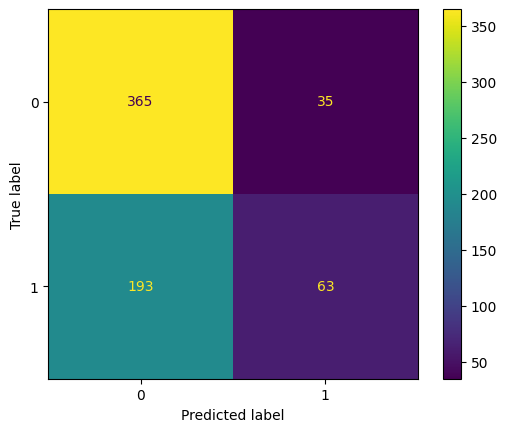

In [54]:
# GRADIENT BOOSTING MODELİNİ İÇE AKTARIYORUZ
from sklearn.ensemble import GradientBoostingClassifier

# MODELİ OLUŞTURUYORUZ
gb_model = GradientBoostingClassifier(
    n_estimators=100,      # 100 AĞAÇ OLUŞTURUYORUZ
    learning_rate=0.1,     # HER AĞACIN KATKISINI BELİRLİYORUZ
    max_depth=3,           # HER AĞACIN DERİNLİĞİNİ 3 İLE SINIRLIYORUZ
    random_state=42        # SONUÇLARIN TEKRARLANABİLMESİNİ SAĞLIYORUZ
)

# MODELİ EĞİTİM VERİSİYLE EĞİTİYORUZ
gb_model.fit(X_train, y_train)

# TEST VERİSİ ÜZERİNDE TAHMİN YAPIYORUZ
y_pred_gb = gb_model.predict(X_test)

# MODELİN BAŞARISINI HESAPLIYORUZ
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

print("GRADIENT BOOSTING SONUÇLARI")
print("ACCURACY:", round(accuracy_score(y_test, y_pred_gb), 3))
print("PRECISION:", round(precision_score(y_test, y_pred_gb, zero_division=0), 3))
print("RECALL:", round(recall_score(y_test, y_pred_gb, zero_division=0), 3))
print("F1:", round(f1_score(y_test, y_pred_gb, zero_division=0), 3))

# HER İKİ SINIF İÇİN AYRINTILI SONUÇLARI GÖSTERİYORUZ
print("\nSINIFLANDIRMA RAPORU:")
print(classification_report(y_test, y_pred_gb, zero_division=0))

# TAHMİNLERİN HATA DAĞILIMINI GÖSTERİYORUZ
cm_gb = confusion_matrix(y_test, y_pred_gb)
print("KARIŞIKLIK MATRİSİ:")
print(cm_gb)

# KARIŞIKLIK MATRİSİNİ GÖRSELLEŞTİRİYORUZ
ConfusionMatrixDisplay(confusion_matrix=cm_gb).plot()
plt.show()


In [55]:
# GRADIENT BOOSTING İÇİN DENENECEK PARAMETRELERİ BELİRLİYORUZ
param_grid_gb = {
    "n_estimators": [100, 200], # ağaç sayısı
    "learning_rate": [0.05, 0.1],# her ağacın katkısı
    "max_depth": [2, 3] #ağaçların karmaşıklık derecesi
}

# GRADIENT BOOSTING MODELİNİ OLUŞTURUYORUZ
gb_base = GradientBoostingClassifier(random_state=42)

# 8 PARAMETRE KOMBİNASYONUNU 5 KATLI ÇAPRAZ DOĞRULAMAYLA DEĞERLENDİRİYORUZ
gb_search = GridSearchCV(
    estimator=gb_base,
    param_grid=param_grid_gb,
    scoring="f1",
    cv=5,
    n_jobs=-1,
    refit=True,
    verbose=2
)

# MODELİ EĞİTİYORUZ VE EN İYİ PARAMETRELERİ ARIYORUZ
gb_search.fit(X_train, y_train)

# EN İYİ PARAMETRELERİ VE ÇAPRAZ DOĞRULAMA F1 PUANINI GÖSTERİYORUZ
print("EN İYİ PARAMETRELER:", gb_search.best_params_)
print("EN İYİ ORTALAMA CV F1:", round(gb_search.best_score_, 3))

# EN İYİ MODELLE TEST VERİSİ ÜZERİNDE TAHMİN YAPIYORUZ
y_pred_gb_best = gb_search.best_estimator_.predict(X_test)

# TEST SONUÇLARINI HESAPLIYORUZ
print("TEST ACCURACY:", round(accuracy_score(y_test, y_pred_gb_best), 3))
print("TEST PRECISION:", round(precision_score(y_test, y_pred_gb_best, zero_division=0), 3))
print("TEST RECALL:", round(recall_score(y_test, y_pred_gb_best, zero_division=0), 3))
print("TEST F1:", round(f1_score(y_test, y_pred_gb_best, zero_division=0), 3))


Fitting 5 folds for each of 8 candidates, totalling 40 fits
EN İYİ PARAMETRELER: {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 200}
EN İYİ ORTALAMA CV F1: 0.384
TEST ACCURACY: 0.654
TEST PRECISION: 0.614
TEST RECALL: 0.305
TEST F1: 0.407


In [57]:

# GEREKLİ KÜTÜPHANELERİ İÇE AKTARIYORUZ
import pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# LOJİSTİK REGRESYON MODELİNİ OLUŞTURUYORUZ
log_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=2000, random_state=42))
])

# MODELİ EĞİTİM VERİSİYLE EĞİTİYORUZ
log_model.fit(X_train, y_train)

# ÜÇ MODELİN TEST TAHMİNLERİNİ OLUŞTURUYORUZ
y_pred_log = log_model.predict(X_test)
y_pred_rf = grid_search.best_estimator_.predict(X_test)
y_pred_gb_best = gb_search.best_estimator_.predict(X_test)

# MODELLERİ VE TAHMİNLERİNİ EŞLEŞTİRİYORUZ
predictions = {
    "Logistic Regression": y_pred_log,
    "Random Forest": y_pred_rf,
    "Gradient Boosting": y_pred_gb_best
}

# HER MODELİN METRİKLERİNİ HESAPLIYORUZ
comparison = []

for name, y_pred in predictions.items():
    comparison.append({
        "MODEL": name,
        "ACCURACY": accuracy_score(y_test, y_pred),
        "PRECISION": precision_score(y_test, y_pred, zero_division=0),
        "RECALL": recall_score(y_test, y_pred, zero_division=0),
        "F1": f1_score(y_test, y_pred, zero_division=0)
    })

# SONUÇLARI F1 PUANINA GÖRE SIRALIYORUZ
comparison_df = pd.DataFrame(comparison)
comparison_df = comparison_df.sort_values("F1", ascending=False)

# KARŞILAŞTIRMA TABLOSUNU GÖSTERİYORUZ
print(comparison_df.round(3).to_string(index=False))


              MODEL  ACCURACY  PRECISION  RECALL    F1
      Random Forest     0.671      0.661   0.320 0.432
  Gradient Boosting     0.654      0.614   0.305 0.407
Logistic Regression     0.610      0.000   0.000 0.000
